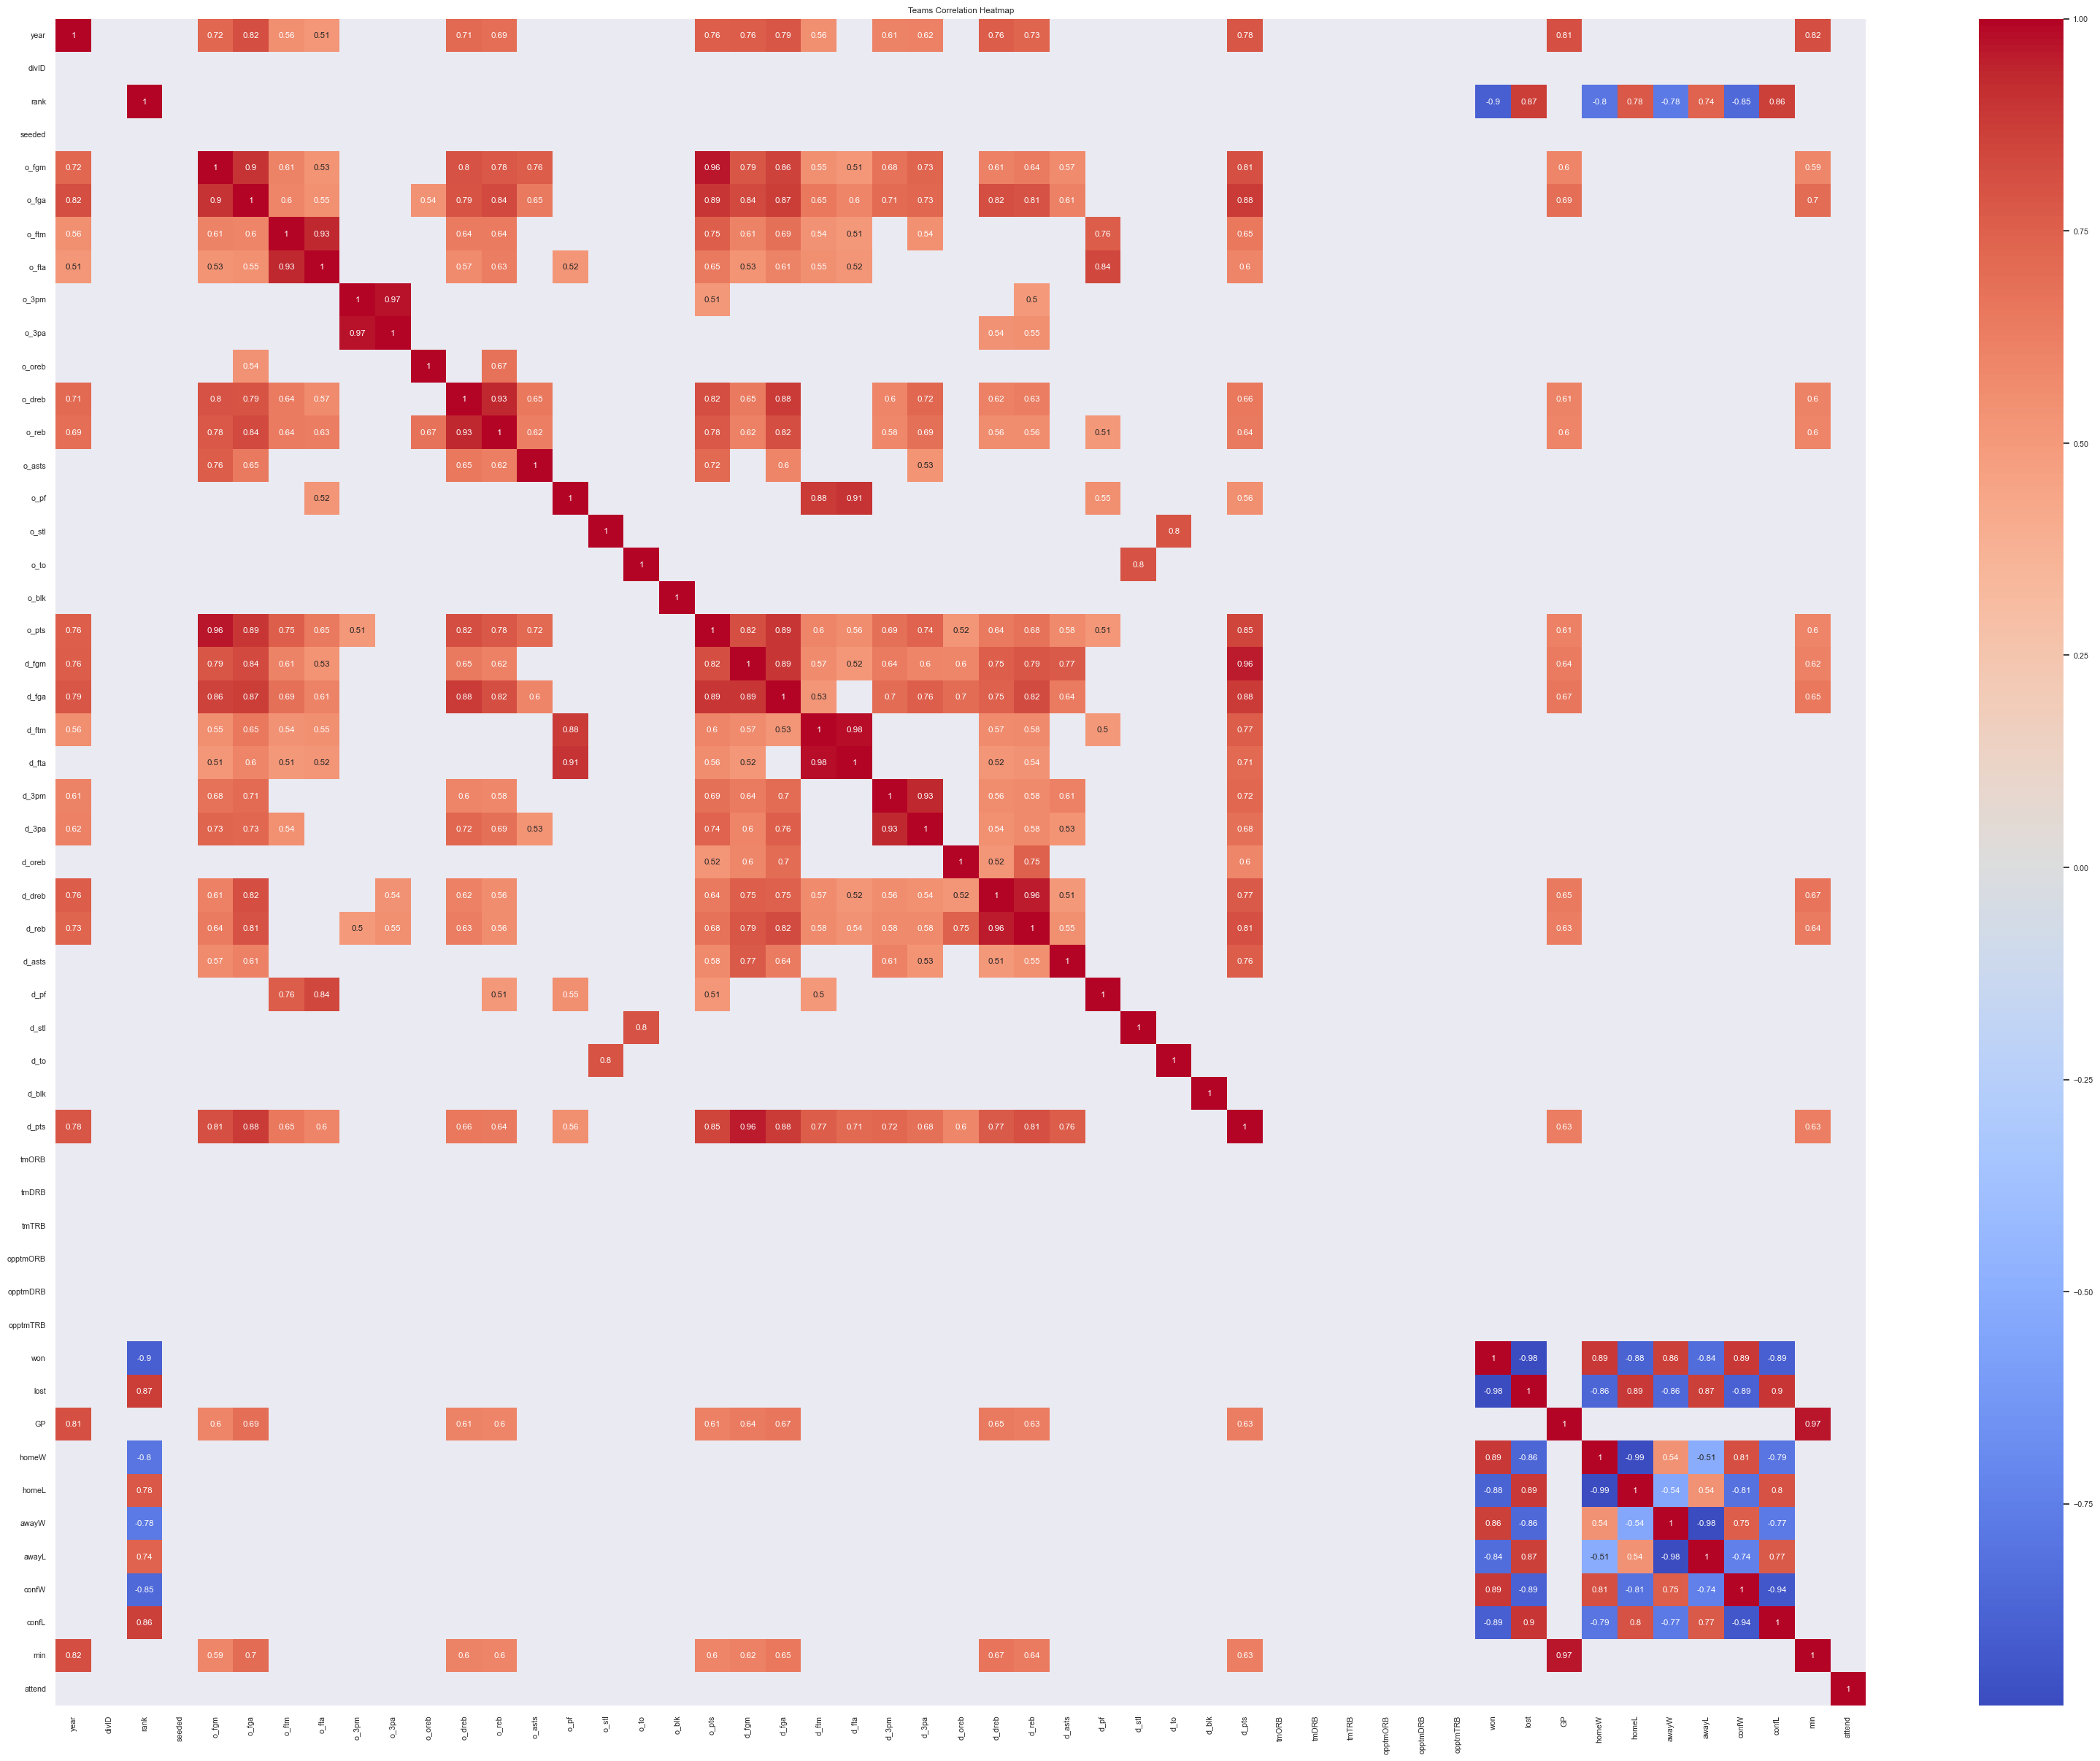

In [107]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

teams_data = pd.read_csv("data/teams.csv")
correlation_matrix = teams_data.corr()

# Generate a mask for the upper triangle
mask = abs(correlation_matrix) < 0.5

# Create a heatmap
plt.figure(figsize=(40, 30))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', mask=mask)

plt.title('Teams Correlation Heatmap')
plt.show()

Com esta correlação podemos concluir quais as features da tabela teams podemos remover antes de aplicar os modelos. Para as features com uma correlação entre 0,95 e 1, realmente não faz sentido ter ambas para prever os resultados.


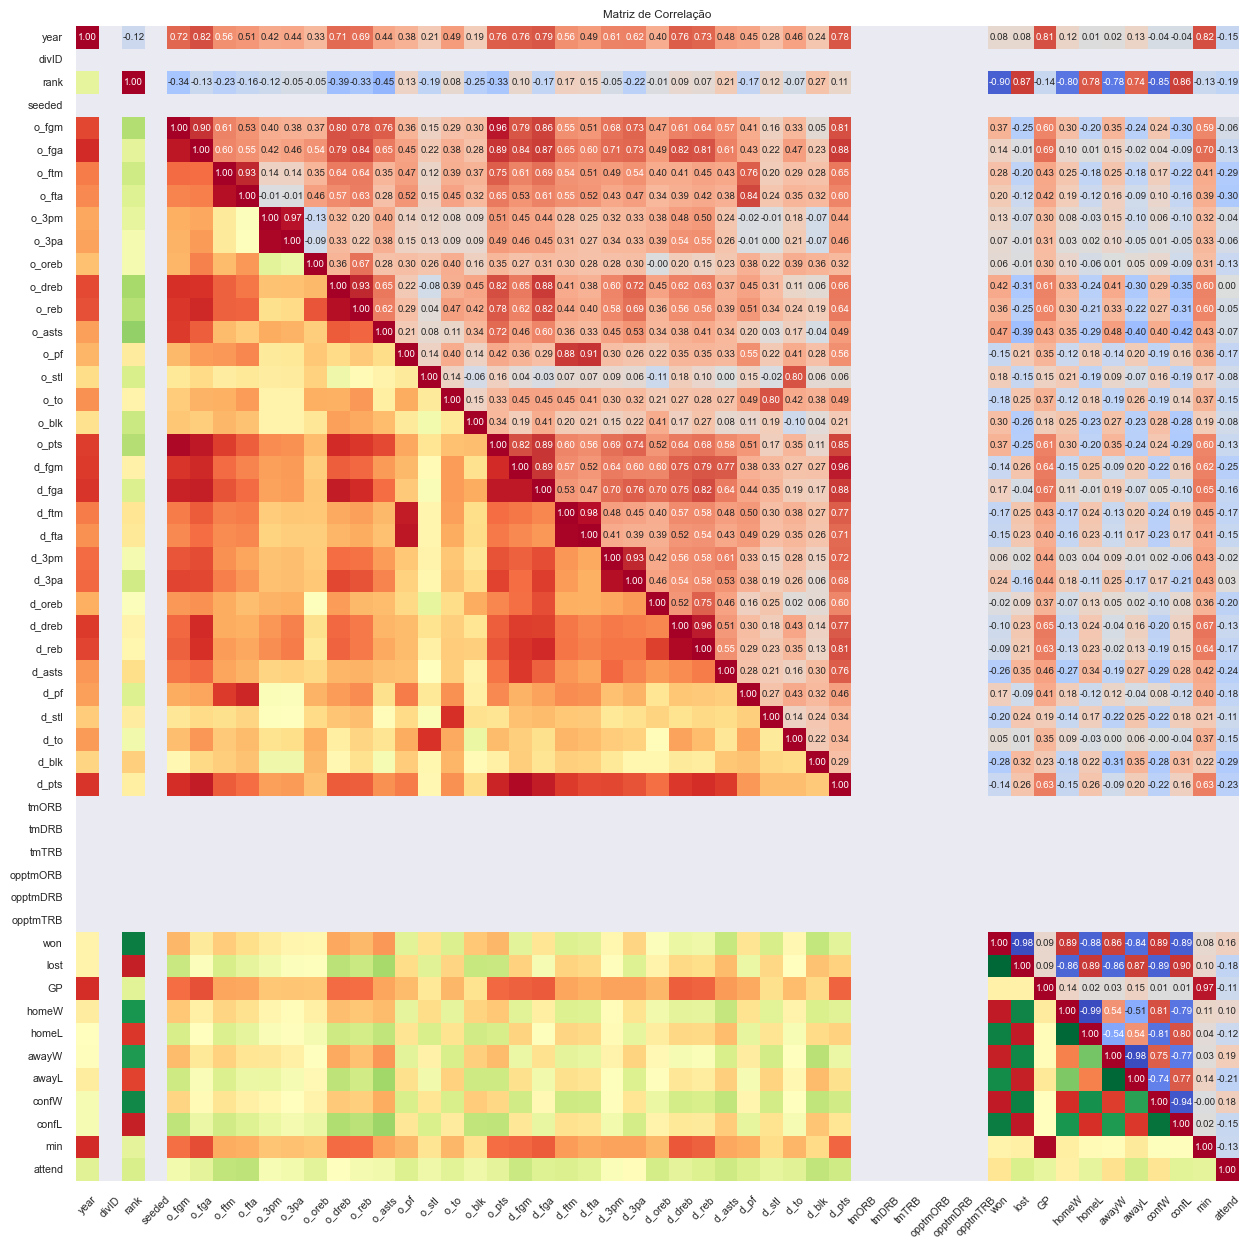

In [108]:
import numpy as np

data_cor = teams_data.select_dtypes(include=[np.number])

# Calcule a matriz de correlação
cor_matrix = data_cor.corr()

# Calcule os níveis de significância
p_vals = data_cor.corr(method="pearson")  # Use o método apropriado aqui, por exemplo, "spearman"

# Crie o gráfico de correlação com estrelas
plt.figure(figsize=(15, 15))
sns.set(font_scale=0.7)  # Ajuste o tamanho da fonte, se necessário

sns.heatmap(cor_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=False,
            annot_kws={"size": 7},
            mask=np.tril(cor_matrix, k=-1))  # Mascara a parte triangular inferior
sns.heatmap(p_vals, fmt="1.0e", cmap="RdYlGn_r", cbar=False,
            annot_kws={"size": 7},
            mask=np.triu(p_vals, k=1))  # Mascara a parte triangular superior

plt.xticks(rotation=45)
plt.title("Matriz de Correlação")
plt.show()

Eliminar atributos:
* 'seeded'
* 'lgID'
* 'divID'
* 'tmORB'
* 'tmDRB'
* 'tmTRB'
* 'opptmORB'
* 'opptmDRB'
* 'opptmTRB'

Data Split

In [109]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
colunas_para_remover = ['franchID','seeded', 'lgID','divID', 'tmORB', 'tmDRB','tmTRB','opptmORB','opptmDRB','opptmTRB']
teams_data = teams_data.drop(columns=colunas_para_remover)

# Colunas a serem codificadas
columns_to_encode = ['confID', 'name', 'tmID','arena']

df_encoded = pd.get_dummies(teams_data, columns=columns_to_encode)

# 'playoff' - tipo inteiro
df_encoded['playoff'] = df_encoded['playoff'].apply(lambda x: 1 if x == 'Y' else 0)

df_encoded['firstRound'] = df_encoded['firstRound'].replace({'L': 0, 'W': 1})
df_encoded['semis'] = df_encoded['semis'].replace({'L': 0, 'W': 1})
df_encoded['finals'] = df_encoded['finals'].replace({'L': 0, 'W': 1})
df_encoded = df_encoded.dropna(subset=['firstRound', 'semis', 'finals']) # Todas as colunas, exceto 'playoff'


teams_test = df_encoded[df_encoded['year'] == 9]
teams_data = df_encoded[df_encoded['year'] < 9]

X_train, X_test, y_train, y_test = teams_data.drop(columns=['playoff']), teams_test.drop(columns=['playoff']), teams_data['playoff'], teams_test['playoff']
                                            

Decision Tree

In [110]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, f1_score

class DecisionTreeModel:
    def __init__(self, X_train, X_test, y_train, y_test):
        self.X_train = X_train.values
        self.X_test = X_test.values
        self.y_train = y_train.values
        self.y_test = y_test.values
        self.algorithm = DecisionTreeClassifier()

    def train(self):
        clf = self.algorithm.fit(self.X_train, self.y_train)
        return clf

    def predict(self, clf):
        return clf.predict(self.X_test)

    def evaluate(self, pred):
        return {
            'accuracy': accuracy_score(self.y_test, pred),
            'f1_score': f1_score(self.y_test, pred)
        }

    def confusion_matrix(self, pred):
        cm = confusion_matrix(self.y_test, pred)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No', 'Yes'])
        disp.plot()


SVM

In [111]:
from sklearn import svm
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, f1_score

class SVMModel:
    def __init__(self, X_train, X_test, y_train, y_test):
        self.X_train = X_train.values
        self.X_test = X_test.values
        self.y_train = y_train.values
        self.y_test = y_test.values
        self.algorithm = svm.SVC()

    def train(self):
        clf = self.algorithm.fit(self.X_train, self.y_train)
        return clf

    def predict(self, clf):
        return clf.predict(self.X_test)

    def evaluate(self, pred):
        return {
            'accuracy': accuracy_score(self.y_test, pred),
            'f1_score': f1_score(self.y_test, pred)
        }

    def confusion_matrix(self, pred):
        cm = confusion_matrix(self.y_test, pred)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No', 'Yes'])
        disp.plot()


Neural Network

In [112]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, f1_score

class NeuralNetworkModel:
    def __init__(self, X_train, X_test, y_train, y_test):
        self.X_train = X_train.values
        self.X_test = X_test.values
        self.y_train = y_train.values
        self.y_test = y_test.values
        self.algorithm = MLPClassifier()

    def train(self):
        clf = self.algorithm.fit(self.X_train, self.y_train)
        return clf

    def predict(self, clf):
        return clf.predict(self.X_test)

    def evaluate(self, pred):
        return {
            'accuracy': accuracy_score(self.y_test, pred),
            'f1_score': f1_score(self.y_test, pred)
        }

    def confusion_matrix(self, pred):
        cm = confusion_matrix(self.y_test, pred)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No', 'Yes'])
        disp.plot()
